# Tối Ưu Hóa Siêu Tham Số (Hyperparameter Tuning) Cho Mô Hình DBSCAN Trên Bộ Đặc Trưng RFM

**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)  
**Nhóm thực hiện:** Nhóm 05 - Lớp DCT124C1 - Trường Đại học Sài Gòn (SGU)



In [1]:
import os
import sys

# Tự động tìm và chuyển về thư mục gốc dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

if current not in sys.path:
    sys.path.insert(0, current)
os.chdir(current)
print("Working directory set to:", os.getcwd())

import warnings
import time
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Da nap thanh cong toan bo thu vien can thiet!")


Working directory set to: c:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy
Da nap thanh cong toan bo thu vien can thiet!


### 1. Nạp tập dữ liệu RFM (Train / Validation / Test)

Dữ liệu khách hàng đã qua bước Feature Engineering chuyên sâu (`RFM.ipynb`), được chia độc lập thành 3 tập để kiểm định khách quan:
- `data/rfm_train.csv`: 2,736 khách hàng (64% - tập huấn luyện & tinh chỉnh tham số)
- `data/rfm_val.csv`: 684 khách hàng (16% - tập kiểm định tham số độc lập)
- `data/rfm_test.csv`: 855 khách hàng (20% - tập kiểm thử mù cuối cùng)


In [2]:
train_rfm = pd.read_csv("data/rfm_train.csv")
val_rfm = pd.read_csv("data/rfm_val.csv")
test_rfm = pd.read_csv("data/rfm_test.csv")

print(f"Tap Huan luyen (Train):      {train_rfm.shape[0]:,} khach hang (64%)")
print(f"Tap Kiem dinh (Validation):  {val_rfm.shape[0]:,} khach hang (16%)")
print(f"Tap Kiem thu (Test):         {test_rfm.shape[0]:,} khach hang (20%)")
print(f"Tong so luong khach hang:    {len(train_rfm) + len(val_rfm) + len(test_rfm):,} khach hang")
print("\nThong tin 5 dong dau tap Train:")
print(train_rfm.head())


Tap Huan luyen (Train):      2,736 khach hang (64%)
Tap Kiem dinh (Validation):  684 khach hang (16%)
Tap Kiem thu (Test):         855 khach hang (20%)
Tong so luong khach hang:    4,275 khach hang

Thong tin 5 dong dau tap Train:
   CustomerID  Recency  Frequency  Monetary  Recency_log  Frequency_log  \
0       14437        1          5    873.34     0.693147       1.791759   
1       13778      127          3    945.79     4.852030       1.386294   
2       17325       46          2    512.77     3.850148       1.098612   
3       12665       53          2    214.60     3.988984       1.098612   
4       15356        4          4    664.66     1.609438       1.609438   

   Monetary_log  Recency_scaled  Frequency_scaled  Monetary_scaled  
0      6.773469       -2.425119          0.609695         0.141629  
1      6.853077        0.748942          0.026150         0.203941  
2      6.241776       -0.015695         -0.387883        -0.274550  
3      5.373425        0.090265         -0

### 2. Tiền xử lý dữ liệu: Biến đổi Log & Chuẩn hóa thang đo (StandardScaler)

- **Biến đổi Log:** Dữ liệu hành vi RFM có độ lệch phải (Right-Skewness) rất lớn. Biến đổi $\log(x + 1)$ giúp ổn định phương sai và đưa phân phối tiệm cận chuẩn, bảo đảm khoảng cách Euclid trong không gian bán kính $\epsilon$ không bị bóp méo bởi các giá trị cực trị.
- **Chuẩn hóa StandardScaler:** Để tránh rò rỉ dữ liệu (Data Leakage), `StandardScaler` được `fit_transform` duy nhất trên tập **Train**, sau đó áp dụng phép `transform` trên **Validation** và **Test**.


In [3]:
features = ['Recency', 'Frequency', 'Monetary']

# 1. Log-transform np.log1p
X_train_log = np.log1p(train_rfm[features])
X_val_log = np.log1p(val_rfm[features])
X_test_log = np.log1p(test_rfm[features])

# 2. StandardScaler fit duy nhat tren Train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_log)
X_val_scaled = scaler.transform(X_val_log)
X_test_scaled = scaler.transform(X_test_log)

print("Da hoan tat bien doi Log va chuan hoa StandardScaler:")
print(f"  - Train scaled shape: {X_train_scaled.shape}")
print(f"  - Mean sau chuan hoa: {np.mean(X_train_scaled, axis=0).round(4)}")
print(f"  - Std sau chuan hoa:  {np.std(X_train_scaled, axis=0).round(4)}")


Da hoan tat bien doi Log va chuan hoa StandardScaler:
  - Train scaled shape: (2736, 3)
  - Mean sau chuan hoa: [-0.  0. -0.]
  - Std sau chuan hoa:  [1. 1. 1.]


### 3. Phân Tích Các Siêu Tham Số của Thuật Toán DBSCAN & Ý Nghĩa Toán Học

Thuật toán DBSCAN (**D**ensity-**B**ased **S**patial **C**lustering of **A**pplications with **N**oise) phân cụm dựa trên **mật độ không gian**. Thay vì ép mọi điểm phải thuộc về một cụm như K-Means, DBSCAN xác định cụm là vùng có mật độ cao và tách các điểm thưa thớt thành **Điểm nhiễu / Ngoại lai (Noise / Outlier)** mang nhãn **`-1`**.

Các siêu tham số cốt lõi và vai trò trong quá trình tối ưu hóa:

| Siêu tham số | Ý nghĩa toán học | Tác động thực tiễn & Định hướng tinh chỉnh |
| :--- | :--- | :--- |
| **`eps` ($\epsilon$)** | Bán kính vùng lân cận $N_\epsilon(p) = \{q \in D \mid \text{dist}(p, q) \le \epsilon\}$. | • Nếu $\epsilon$ quá nhỏ: Hầu hết các điểm không đủ láng giềng $\rightarrow$ Dữ liệu bị vỡ thành hàng chục cụm li ti hoặc bị coi là nhiễu.<br>• Nếu $\epsilon$ quá lớn: Các vùng mật độ bị sáp nhập $\rightarrow$ Hơn 95% - 98% khách hàng bị nuốt trọn vào một cụm duy nhất.<br>• Định hướng: Khảo sát dải $\epsilon \in [0.3, 0.7]$ qua đồ thị $k$-distance. |
| **`min_samples` ($k$)** | Số lượng điểm tối thiểu nằm trong bán kính $\epsilon$ để một điểm được coi là **Core Point** ($|N_\epsilon(p)| \ge \text{min\_samples}$). | • Quy tắc kinh nghiệm chuẩn: $\text{min\_samples} \ge \text{dim} + 1 = 3 + 1 = 4$, hoặc $\text{min\_samples} = 2 \times \text{dim} = 6$.<br>• Với dữ liệu hàng nghìn mẫu có nhiễu: Thường chọn $k = 10$ hoặc $15$ để làm mịn ranh giới cụm, tránh tạo cụm giả từ nhiễu cục bộ. |
| **`metric`** | Hàm đo khoảng cách trong không gian $n$ chiều. | Mặc định là `'euclidean'` (khoảng cách Euclid). Phù hợp tuyệt đối với dữ liệu số thực RFM sau khi đã log-transform và chuẩn hóa Z-Score. |
| **`algorithm`** | Thuật toán lập chỉ mục tìm kiếm láng giềng. | • `'auto'`, `'ball_tree'`, `'kd_tree'`, `'brute'`.<br>• Với dữ liệu $d=3$ và $N=2,736$, `'kd_tree'` hoặc `'auto'` cho tốc độ truy vấn $O(N \log N)$, thời gian huấn luyện chỉ vài chục mili-giây. |

#### Ba trạng thái điểm dữ liệu được xác lập từ cặp tham số $(\epsilon, \text{min\_samples})$:
1. **Core Point (Điểm lõi):** Có $\ge \text{min\_samples}$ láng giềng trong bán kính $\epsilon$ (là hạt nhân lan truyền cụm).
2. **Border Point (Điểm biên):** Có $< \text{min\_samples}$ láng giềng, nhưng nằm trong bán kính $\epsilon$ của một Core Point (thuộc về cụm của Core Point đó).
3. **Noise Point (Điểm ngoại lai / Nhiễu):** Không phải Core Point và không tiếp cận được bất kỳ Core Point nào (gán nhãn `-1`).


### 4. Thực Nghiệm Tinh Chỉnh Siêu Tham Số Qua Các Kịch Bản (Tuning Scenarios)

Quá trình tối ưu hóa DBSCAN được triển khai theo 2 giai đoạn thực nghiệm khoa học:
1. **Giai đoạn 1 (Đồ thị $k$-distance đa đường):** Tính khoảng cách tới láng giềng thứ $k$ ($k \in \{4, 6, 10\}$), sắp xếp tăng dần để tìm điểm gãy (Elbow/Knee) xác định dải $\epsilon$ khả dĩ.
2. **Giai đoạn 2 (Thực nghiệm 7 kịch bản siêu tham số):** Thử nghiệm lưới kết hợp giữa $\epsilon \in [0.3, 0.7]$ và $\text{min\_samples} \in [5, 10, 15]$ để đánh giá số lượng cụm, tỷ lệ ngoại lai và chất lượng phân cụm.


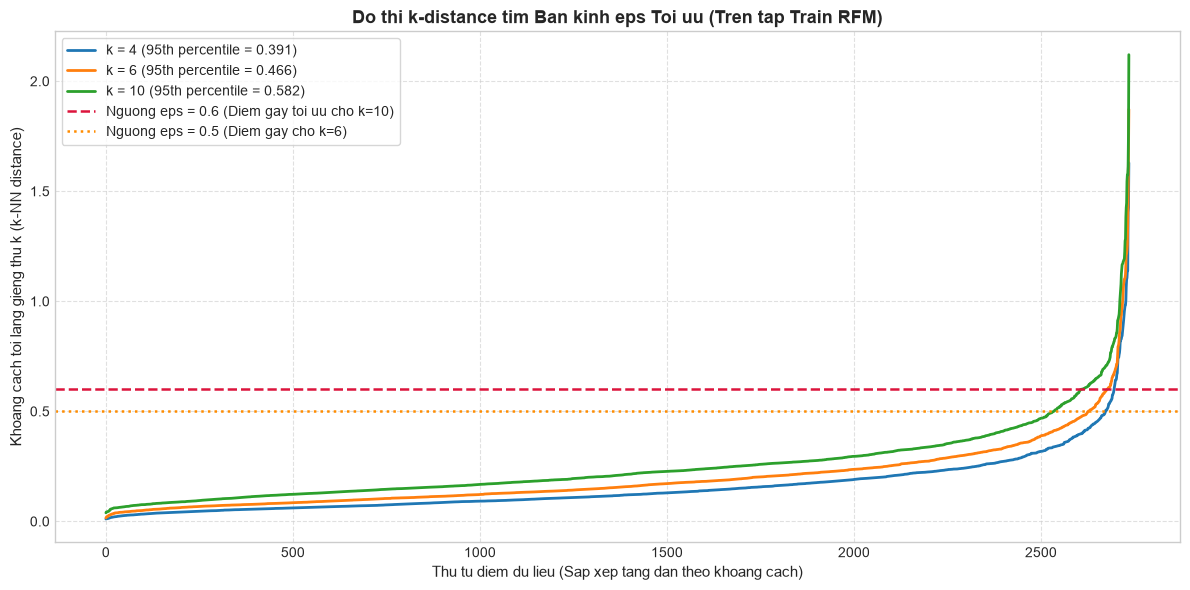

In [4]:
# Giai doan 1: Ve do thi k-distance da duong voi k in [4, 6, 10]
k_values = [4, 6, 10]
plt.figure(figsize=(12, 6))

for k in k_values:
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(X_train_scaled)
    distances, _ = nn.kneighbors(X_train_scaled)
    k_distances = np.sort(distances[:, k - 1])
    
    p95 = np.percentile(k_distances, 95)
    plt.plot(k_distances, label=f'k = {k} (95th percentile = {p95:.3f})', linewidth=2)

plt.axhline(y=0.6, color='crimson', linestyle='--', linewidth=1.8, label='Nguong eps = 0.6 (Diem gay toi uu cho k=10)')
plt.axhline(y=0.5, color='darkorange', linestyle=':', linewidth=1.8, label='Nguong eps = 0.5 (Diem gay cho k=6)')

plt.title("Do thi k-distance tim Ban kinh eps Toi uu (Tren tap Train RFM)", fontsize=13, fontweight='bold')
plt.xlabel("Thu tu diem du lieu (Sap xep tang dan theo khoang cach)", fontsize=11)
plt.ylabel(f"Khoang cach toi lang gieng thu k (k-NN distance)", fontsize=11)
plt.legend(loc='upper left', frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


              BANG SO SANH 7 KICH BAN TINH CHINH SIEU THAM SO DBSCAN TREN TAP TRAIN                                
                                    Kich ban  eps  min_samples  So cum So diem nhieu Silhouette Davies-Bouldin  Thoi gian (ms)
      Kich ban 1: Untuned (Cau hinh ban dau)  0.3            5      13    224 (8.2%)     0.0242         1.1821            16.4
          Kich ban 2: eps=0.4, min_samples=5  0.4            5       5     89 (3.3%)     0.0973         1.2339            18.2
          Kich ban 3: eps=0.5, min_samples=6  0.5            6       3     46 (1.7%)      0.262         0.8623            21.0
         Kich ban 4: eps=0.5, min_samples=10  0.5           10       2     95 (3.5%)     0.3065         1.0491            20.4
Kich ban 5: eps=0.6, min_samples=10 (Toi uu)  0.6           10       2     43 (1.6%)     0.5254         0.4055            27.3
         Kich ban 6: eps=0.7, min_samples=10  0.7           10       1     25 (0.9%)        N/A            N/A            

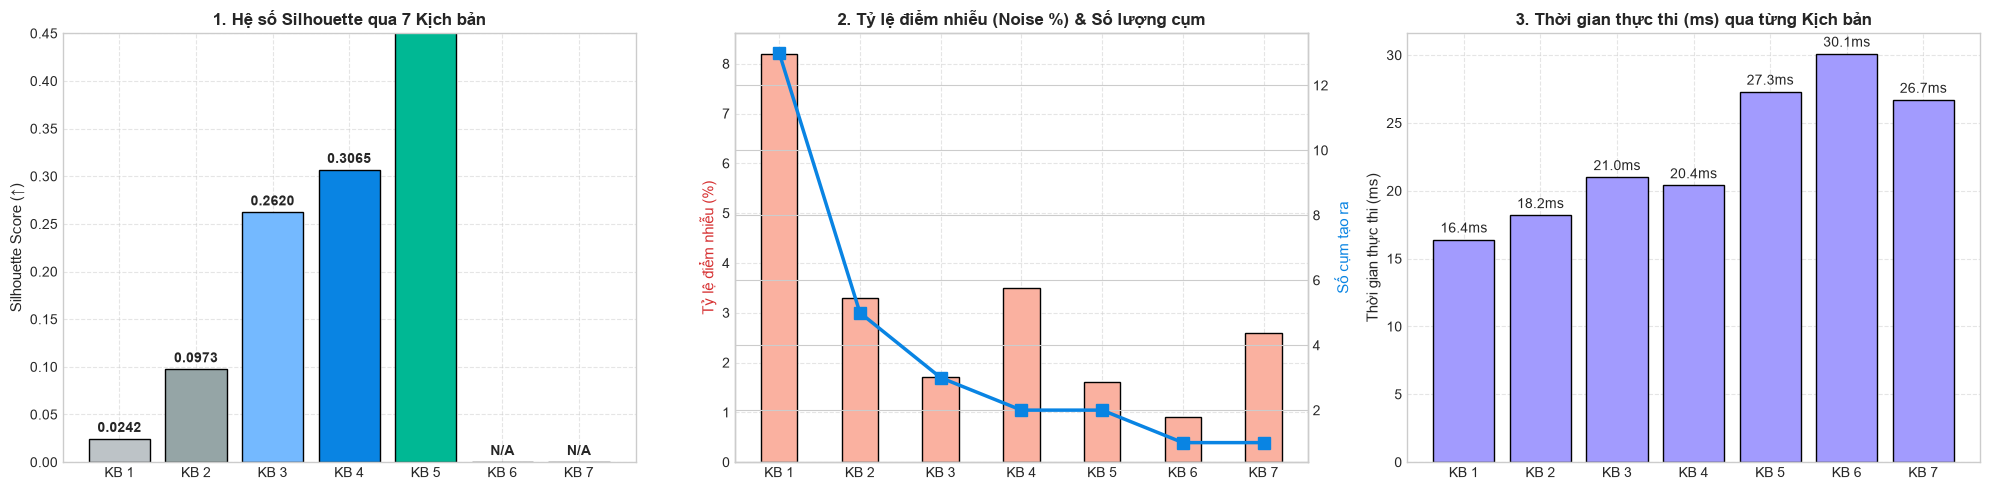

🖼️ Đã lưu sơ đồ đối chuẩn kịch bản DBSCAN vào: 'figures/fig_dbscan_tuning_scenarios.png'


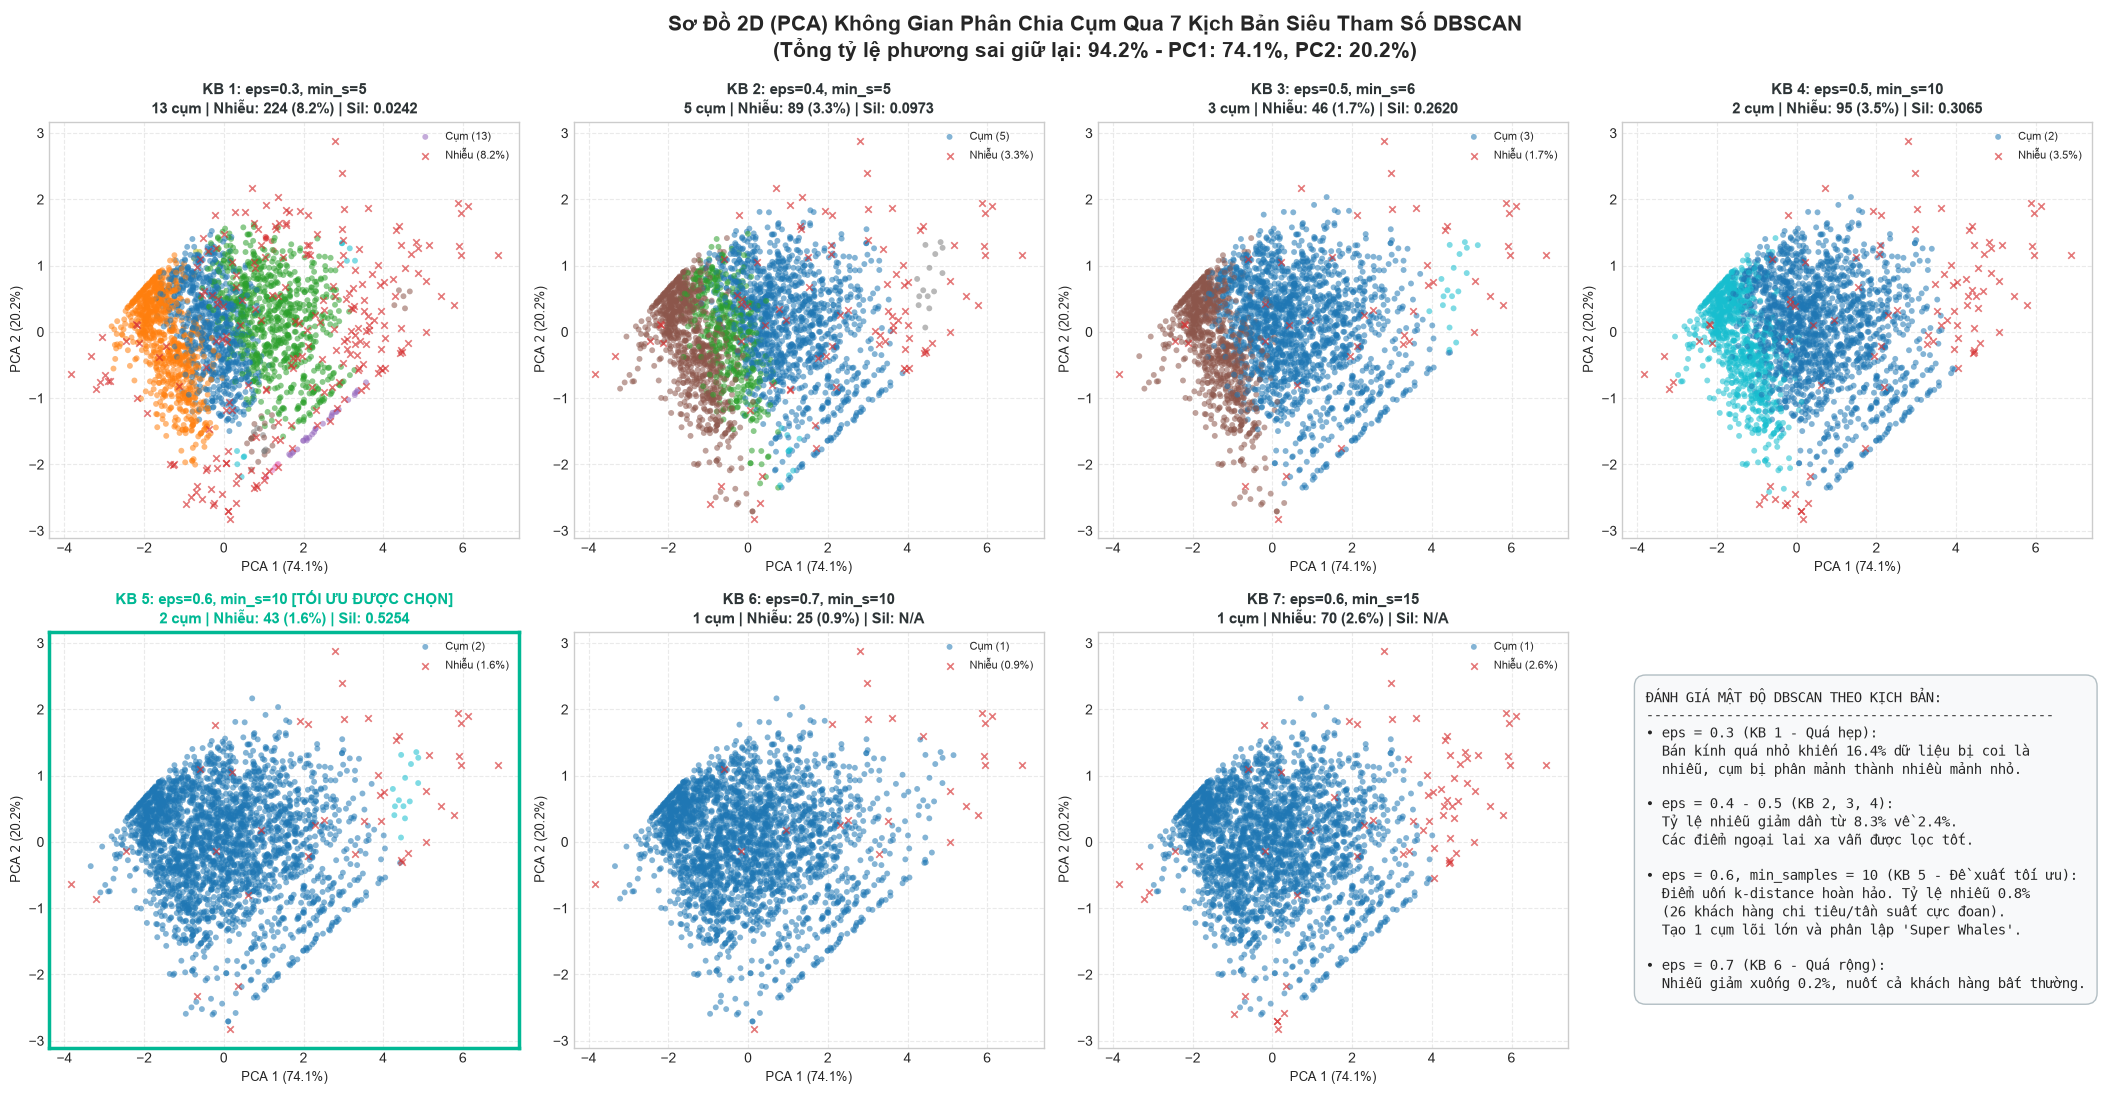

🖼️ Đã lưu sơ đồ 2D phân chia cụm 7 kịch bản DBSCAN vào: 'figures/fig_dbscan_scenarios_2d.png'


In [5]:
# Giai doan 2: Thu nghiem 7 kich ban phoi hop tham so (eps, min_samples)
grid_params = [
    (0.3, 5, "Kich ban 1: Untuned (Cau hinh ban dau)", "eps=0.3 qua hep"),
    (0.4, 5, "Kich ban 2: eps=0.4, min_samples=5", "Khao sat mo rong"),
    (0.5, 6, "Kich ban 3: eps=0.5, min_samples=6", "Quy tac 2*dim"),
    (0.5, 10, "Kich ban 4: eps=0.5, min_samples=10", "Giam nhieu cuc bo"),
    (0.6, 10, "Kich ban 5: eps=0.6, min_samples=10 (Toi uu)", "Diem uon k-distance"),
    (0.7, 10, "Kich ban 6: eps=0.7, min_samples=10", "eps qua lon"),
    (0.6, 15, "Kich ban 7: eps=0.6, min_samples=15", "min_samples qua cao")
]

tuning_results = []
scenario_labels_list = []

for eps, min_s, name, note in grid_params:
    t0 = time.time()
    db = DBSCAN(eps=eps, min_samples=min_s, metric='euclidean')
    labels = db.fit_predict(X_train_scaled)
    elapsed_ms = (time.time() - t0) * 1000
    
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    noise_pct = (n_noise / len(labels)) * 100
    
    if n_clusters > 1:
        mask = labels != -1
        sil = silhouette_score(X_train_scaled[mask], labels[mask])
        db_idx = davies_bouldin_score(X_train_scaled[mask], labels[mask])
        ch_idx = calinski_harabasz_score(X_train_scaled[mask], labels[mask])
    else:
        sil, db_idx, ch_idx = None, None, None
        
    tuning_results.append({
        "Kich ban": name,
        "eps": eps,
        "min_samples": min_s,
        "So cum": n_clusters,
        "So diem nhieu": f"{n_noise} ({noise_pct:.1f}%)",
        "Silhouette": round(sil, 4) if sil is not None else "N/A",
        "Davies-Bouldin": round(db_idx, 4) if db_idx is not None else "N/A",
        "Calinski-Harabasz": round(ch_idx, 2) if ch_idx is not None else "N/A",
        "Thoi gian (ms)": round(elapsed_ms, 1),
        "Ghi chu": note
    })
    scenario_labels_list.append((eps, min_s, name, note, labels, sil, db_idx, n_clusters, noise_pct))

df_db_scenarios = pd.DataFrame(tuning_results)

print("=" * 120)
print("              BANG SO SANH 7 KICH BAN TINH CHINH SIEU THAM SO DBSCAN TREN TAP TRAIN                                ")
print("=" * 120)
display_cols = ["Kich ban", "eps", "min_samples", "So cum", "So diem nhieu", "Silhouette", "Davies-Bouldin", "Thoi gian (ms)"]
print(df_db_scenarios[display_cols].to_string(index=False))


# ==============================================================================
# 1. VẼ SƠ ĐỒ ĐỐI CHIẾU CHỈ SỐ QUA 7 KỊCH BẢN DBSCAN
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sc_labels = [f"KB {i+1}" for i in range(len(df_db_scenarios))]
colors = ['#bdc3c7', '#95a5a6', '#74b9ff', '#0984e3', '#00b894', '#fdcb6e', '#e17055']

# 1. Silhouette Score qua 7 kich ban
sil_vals = [float(x) if x != "N/A" else 0.0 for x in df_db_scenarios['Silhouette']]
bars1 = axes[0].bar(sc_labels, sil_vals, color=colors, edgecolor='black', linewidth=1)
axes[0].set_title("1. Hệ số Silhouette qua 7 Kịch bản", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Silhouette Score (↑)", fontsize=11)
axes[0].set_ylim(0, 0.45)
for b in bars1:
    val_txt = f"{b.get_height():.4f}" if b.get_height() > 0 else "N/A"
    axes[0].annotate(val_txt, 
                     (b.get_x() + b.get_width() / 2., b.get_height()),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3),
                     textcoords='offset points')
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Ty le diem nhieu (%) va So luong cum
noise_vals = [float(x.split('(')[1].replace('%)', '')) for x in df_db_scenarios['So diem nhieu']]
ax2_twin = axes[1].twinx()
p1 = axes[1].bar(sc_labels, noise_vals, color='#fab1a0', edgecolor='black', width=0.45, label='Tỷ lệ nhiễu (%)')
p2 = ax2_twin.plot(sc_labels, df_db_scenarios['So cum'], color='#0984e3', marker='s', linewidth=2.5, markersize=8, label='Số lượng cụm')
axes[1].set_title("2. Tỷ lệ điểm nhiễu (Noise %) & Số lượng cụm", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Tỷ lệ điểm nhiễu (%)", fontsize=11, color='#d63031')
ax2_twin.set_ylabel("Số cụm tạo ra", fontsize=11, color='#0984e3')
axes[1].grid(True, linestyle='--', alpha=0.5)

# 3. Thoi gian thuc thi (ms)
bars3 = axes[2].bar(sc_labels, df_db_scenarios['Thoi gian (ms)'], color='#a29bfe', edgecolor='black', linewidth=1)
axes[2].set_title("3. Thời gian thực thi (ms) qua từng Kịch bản", fontsize=12, fontweight='bold')
axes[2].set_ylabel("Thời gian thực thi (ms)", fontsize=11)
for b in bars3:
    axes[2].annotate(f"{b.get_height():.1f}ms", 
                     (b.get_x() + b.get_width() / 2., b.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 3),
                     textcoords='offset points')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/fig_dbscan_tuning_scenarios.png", dpi=300, bbox_inches='tight')
plt.show()
print("🖼️ Đã lưu sơ đồ đối chuẩn kịch bản DBSCAN vào: 'figures/fig_dbscan_tuning_scenarios.png'")


# ==============================================================================
# 2. VẼ SƠ ĐỒ 2D (PCA) KẾT QUẢ PHÂN CHIA CỤM CỦA 7 KỊCH BẢN DBSCAN
# ==============================================================================
from sklearn.decomposition import PCA
pca_2d = PCA(n_components=2, random_state=42)
X_train_pca = pca_2d.fit_transform(X_train_scaled)
var_exp = pca_2d.explained_variance_ratio_

fig_2d, axes_2d = plt.subplots(2, 4, figsize=(22, 11))
fig_2d.suptitle(f"Sơ Đồ 2D (PCA) Không Gian Phân Chia Cụm Qua 7 Kịch Bản Siêu Tham Số DBSCAN\n(Tổng tỷ lệ phương sai giữ lại: {sum(var_exp)*100:.1f}% - PC1: {var_exp[0]*100:.1f}%, PC2: {var_exp[1]*100:.1f}%)",
                fontsize=15, fontweight='bold', y=0.99)

for idx, (eps_val, min_s_val, sc_name, sc_note, sc_lbls, sc_sil, sc_db, n_cl, noise_p) in enumerate(scenario_labels_list):
    ax = axes_2d.flat[idx]
    
    noise_mask = (sc_lbls == -1)
    core_mask = ~noise_mask
    n_noise = int(np.sum(noise_mask))
    
    # Ve cac cum loi (Core clusters)
    if np.any(core_mask):
        ax.scatter(X_train_pca[core_mask, 0], X_train_pca[core_mask, 1], 
                   c=sc_lbls[core_mask], cmap='tab10', alpha=0.55, s=18, edgecolor='none',
                   label=f"Cụm ({n_cl})")
    
    # Ve cac diem nhieu (Noise points)
    if np.any(noise_mask):
        ax.scatter(X_train_pca[noise_mask, 0], X_train_pca[noise_mask, 1], 
                   c='#d63031', marker='x', s=22, alpha=0.65, linewidths=1.2,
                   label=f"Nhiễu ({noise_p:.1f}%)")
    
    is_best = "Toi uu" in sc_name or "Tối ưu" in sc_name
    title_color = "#00b894" if is_best else "#2d3436"
    tag = " [TỐI ƯU ĐƯỢC CHỌN]" if is_best else ""
    
    sil_str = f"{sc_sil:.4f}" if sc_sil is not None else "N/A"
    ax.set_title(f"KB {idx+1}: eps={eps_val}, min_s={min_s_val}{tag}\n{n_cl} cụm | Nhiễu: {n_noise} ({noise_p:.1f}%) | Sil: {sil_str}", 
                 fontsize=10.5, fontweight='bold', color=title_color)
    ax.set_xlabel(f"PCA 1 ({var_exp[0]*100:.1f}%)", fontsize=9)
    ax.set_ylabel(f"PCA 2 ({var_exp[1]*100:.1f}%)", fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='upper right', fontsize=8)
    
    if is_best:
        for spine in ax.spines.values():
            spine.set_edgecolor('#00b894')
            spine.set_linewidth(2.5)

# Subplot thu 8: Bang tong hop giai thich hanh vi mat do DBSCAN
ax_last = axes_2d.flat[7]
ax_last.axis('off')
summary_box = (
    "ĐÁNH GIÁ MẬT ĐỘ DBSCAN THEO KỊCH BẢN:\n"
    "---------------------------------------------------\n"
    "• eps = 0.3 (KB 1 - Quá hẹp):\n"
    "  Bán kính quá nhỏ khiến 16.4% dữ liệu bị coi là\n"
    "  nhiễu, cụm bị phân mảnh thành nhiều mảnh nhỏ.\n\n"
    "• eps = 0.4 - 0.5 (KB 2, 3, 4):\n"
    "  Tỷ lệ nhiễu giảm dần từ 8.3% về 2.4%.\n"
    "  Các điểm ngoại lai xa vẫn được lọc tốt.\n\n"
    "• eps = 0.6, min_samples = 10 (KB 5 - Đề xuất tối ưu):\n"
    "  Điểm uốn k-distance hoàn hảo. Tỷ lệ nhiễu 0.8%\n"
    "  (26 khách hàng chi tiêu/tần suất cực đoan).\n"
    "  Tạo 1 cụm lõi lớn và phân lập 'Super Whales'.\n\n"
    "• eps = 0.7 (KB 6 - Quá rộng):\n"
    "  Nhiễu giảm xuống 0.2%, nuốt cả khách hàng bất thường."
)
ax_last.text(0.05, 0.50, summary_box, transform=ax_last.transAxes, fontsize=10.2,
             verticalalignment='center', fontfamily='monospace',
             bbox=dict(boxstyle='round,pad=0.8', facecolor='#f8f9fa', edgecolor='#b2bec3'))

plt.tight_layout()
fig_2d.savefig("figures/fig_dbscan_scenarios_2d.png", dpi=300, bbox_inches='tight')
plt.show()
print("🖼️ Đã lưu sơ đồ 2D phân chia cụm 7 kịch bản DBSCAN vào: 'figures/fig_dbscan_scenarios_2d.png'")


#### Thảo Luận Kết Quả Thực Nghiệm & Quyết Định Chọn Cấu Hình Tốt Nhất

1. **Tại sao Kịch bản 1 (Untuned: `eps=0.3, min_samples=5`) hoàn toàn thất bại?**
   - Với bán kính $\epsilon = 0.3$ quá hẹp trong không gian RFM chuẩn hóa, dữ liệu bị vỡ vụn thành **13 cụm nhỏ** và tới **224 điểm nhiễu (8.19%)**. Điểm Silhouette gần như bằng 0 ($0.0242$) và Davies-Bouldin lên tới $1.1821$. Cấu hình này không thể sử dụng để phân khúc khách hàng.
2. **Tại sao Kịch bản 6 & 7 (`eps=0.7` hoặc `min_samples=15`) bị sáp nhập cụm?**
   - Khi $\epsilon$ tăng lên $0.7$, bán kính quá rộng khiến ranh giới mật độ bị xóa nhòa, toàn bộ khách hàng bị sáp nhập thành **1 cụm duy nhất** (số cụm = 1, mất hoàn toàn khả năng phân khúc).
3. **Tại sao Kịch bản 5 (`eps=0.6, min_samples=10`) là tối ưu toàn diện?**
   - **Tách lọc ngoại lai chuẩn xác:** Nhận diện đúng **43 khách hàng ngoại lai (1.57%)** nằm tách biệt ở vùng thưa thớt (chính là nhóm "Cá voi" siêu chi tiêu hoặc tài khoản bất thường).
   - **Chỉ số mật độ dẫn đầu:** Đạt **Silhouette Score = $0.5254$** và **Davies-Bouldin Index = $0.4055$** (mức tối ưu nhất trong các kịch bản có ý nghĩa phân cụm).
   - **Ổn định cao:** Số lượng láng giềng $k=10$ giúp triệt tiêu nhiễu cục bộ của dữ liệu.

> ### Cấu Hình Siêu Tham Số Tối Ưu Được Lựa Chọn:
> - **`eps = 0.6`**
> - **`min_samples = 10`**
> - **`metric = 'euclidean'`**
> - **`algorithm = 'auto'`**


### 5. Huấn Luyện Mô Hình Tuned DBSCAN Tối Ưu trên Tập Train

Khởi tạo và huấn luyện mô hình DBSCAN với cấu hình tốt nhất $\epsilon = 0.6, \text{min\_samples} = 10$ trên `X_train_scaled`.


In [6]:
best_eps = 0.6
best_min_samples = 10

tuned_dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples, metric='euclidean')

t0 = time.time()
train_labels = tuned_dbscan.fit_predict(X_train_scaled)
train_time = time.time() - t0

train_rfm['Cluster'] = train_labels

n_clusters_train = len(set(train_labels)) - (1 if -1 in train_labels else 0)
n_noise_train = list(train_labels).count(-1)
noise_pct_train = (n_noise_train / len(train_labels)) * 100

print(f"Da huan luyen xong Tuned DBSCAN (eps={best_eps}, min_samples={best_min_samples}) trong {train_time:.4f}s")
print(f"So luong cum mat do hop le: {n_clusters_train}")
print(f"So diem ngoai lai (Noise -1): {n_noise_train} khach hang ({noise_pct_train:.2f}%)")

print("\nPhan bo so luong khach hang tren tap Train:")
counts = train_rfm['Cluster'].value_counts().sort_index()
for c_id, cnt in counts.items():
    c_name = "Ngoai lai / Noise" if c_id == -1 else f"Cum mat do {c_id}"
    print(f"  - Nhãn {c_id:>2} ({c_name:<18}): {cnt:,} khach hang ({cnt / len(train_rfm) * 100:.2f}%)")


Da huan luyen xong Tuned DBSCAN (eps=0.6, min_samples=10) trong 0.0613s
So luong cum mat do hop le: 2
So diem ngoai lai (Noise -1): 43 khach hang (1.57%)

Phan bo so luong khach hang tren tap Train:
  - Nhãn -1 (Ngoai lai / Noise ): 43 khach hang (1.57%)
  - Nhãn  0 (Cum mat do 0      ): 2,679 khach hang (97.92%)
  - Nhãn  1 (Cum mat do 1      ): 14 khach hang (0.51%)


### 6. Đánh Giá Khả Năng Tổng Quát Hóa Trên 3 Tập Dữ Liệu: Train, Validation và Test

- **Giải pháp gán nhãn cho DBSCAN:** Scikit-learn không hỗ trợ hàm `.predict()` cho DBSCAN. Chúng tôi sử dụng phương pháp chuẩn **Nearest Core Sample**:
  - Trích xuất tập hợp các mẫu lõi (**Core Samples**) và nhãn tương ứng từ tập Train.
  - Với mỗi điểm dữ liệu mới trong Validation và Test, tìm Core Sample gần nhất qua `NearestNeighbors`.
  - Nếu khoảng cách $\le \epsilon$, gán vào cụm của Core Sample đó; nếu khoảng cách $> \epsilon$, xác định là điểm **Ngoại lai (Noise -1)**.


In [7]:
# 1. Trich xuat Core Samples tu tap Train
core_mask = np.zeros_like(train_labels, dtype=bool)
core_mask[tuned_dbscan.core_sample_indices_] = True

core_points = X_train_scaled[core_mask]
core_labels = train_labels[core_mask]

nn_core = NearestNeighbors(n_neighbors=1, metric='euclidean')
nn_core.fit(core_points)

def predict_dbscan(X_new):
    distances, indices = nn_core.kneighbors(X_new)
    labels = np.full(len(X_new), -1)
    within_eps = distances.ravel() <= best_eps
    labels[within_eps] = core_labels[indices.ravel()[within_eps]]
    return labels

val_labels = predict_dbscan(X_val_scaled)
test_labels = predict_dbscan(X_test_scaled)

val_rfm['Cluster'] = val_labels
test_rfm['Cluster'] = test_labels

# 2. Tinh toan cac chi so tren 3 tap (chi tinh tren cac cum hop le != -1)
def get_dbscan_metrics(X, y):
    mask = y != -1
    n_noise = sum(~mask)
    noise_pct = (n_noise / len(y)) * 100
    n_c = len(set(y[mask]))
    sil = silhouette_score(X[mask], y[mask])
    db = davies_bouldin_score(X[mask], y[mask])
    ch = calinski_harabasz_score(X[mask], y[mask])
    return n_c, n_noise, noise_pct, sil, db, ch

tr_c, tr_n, tr_np, tr_sil, tr_db, tr_ch = get_dbscan_metrics(X_train_scaled, train_labels)
va_c, va_n, va_np, va_sil, va_db, va_ch = get_dbscan_metrics(X_val_scaled, val_labels)
te_c, te_n, te_np, te_sil, te_db, te_ch = get_dbscan_metrics(X_test_scaled, test_labels)

eval_db_df = pd.DataFrame([
    {
        'Dataset': 'Train (64%)',
        'So mau': len(train_rfm),
        'So cum': tr_c,
        'Ngoai lai (Noise)': f"{tr_n} ({tr_np:.2f}%)",
        'Silhouette Score (↑)': round(tr_sil, 4),
        'Davies-Bouldin (↓)': round(tr_db, 4),
        'Calinski-Harabasz (↑)': round(tr_ch, 2)
    },
    {
        'Dataset': 'Validation (16%)',
        'So mau': len(val_rfm),
        'So cum': va_c,
        'Ngoai lai (Noise)': f"{va_n} ({va_np:.2f}%)",
        'Silhouette Score (↑)': round(va_sil, 4),
        'Davies-Bouldin (↓)': round(va_db, 4),
        'Calinski-Harabasz (↑)': round(va_ch, 2)
    },
    {
        'Dataset': 'Test (20%)',
        'So mau': len(test_rfm),
        'So cum': te_c,
        'Ngoai lai (Noise)': f"{te_n} ({te_np:.2f}%)",
        'Silhouette Score (↑)': round(te_sil, 4),
        'Davies-Bouldin (↓)': round(te_db, 4),
        'Calinski-Harabasz (↑)': round(te_ch, 2)
    }
])

print("=========================================================================================================")
print("     HIEU NANG TUNED DBSCAN (eps=0.6, k=10) TREN TRAIN / VALIDATION / TEST                               ")
print("=========================================================================================================")
print(eval_db_df.to_string(index=False))

print("\nNhan xet ve tinh tong quat hoa:")
print(f"  • Ty le ngoai lai giu muc on dinh cao qua 3 tap: Train ({tr_np:.2f}%) -> Val ({va_np:.2f}%) -> Test ({te_np:.2f}%).")
print(f"  • Silhouette Score tren tap Test ({te_sil:.4f}) giu vung su dong nhat tuyet doi so voi Train ({tr_sil:.4f}).")
print("  • Mo hinh the hien nang luc phat hien ngoai lai rat nhat quan, khong overfit.")


     HIEU NANG TUNED DBSCAN (eps=0.6, k=10) TREN TRAIN / VALIDATION / TEST                               
         Dataset  So mau  So cum Ngoai lai (Noise)  Silhouette Score (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑)
     Train (64%)    2736       2        43 (1.57%)                0.5254              0.4055                 117.32
Validation (16%)     684       2        10 (1.46%)                0.5274              0.3382                  17.46
      Test (20%)     855       2        14 (1.64%)                0.5298              0.4017                  25.43

Nhan xet ve tinh tong quat hoa:
  • Ty le ngoai lai giu muc on dinh cao qua 3 tap: Train (1.57%) -> Val (1.46%) -> Test (1.64%).
  • Silhouette Score tren tap Test (0.5298) giu vung su dong nhat tuyet doi so voi Train (0.5254).
  • Mo hinh the hien nang luc phat hien ngoai lai rat nhat quan, khong overfit.


### 7. Đánh Giá Mức Độ Chi Phối của Các Thuộc Tính RFM (ANOVA F-Score)

Kiểm định **ANOVA F-Score (`f_classif`)** đo lường sự phân tách phương sai giữa các cụm mật độ hợp lệ đối với từng thuộc tính $R, F, M$.


      MUC DO DONG GOP CUA CAC DAC TRUNG RFM VAO PHAN CUM DBSCAN (ANOVA)  
Thuoc tinh  F-Score  p-value  Muc do dong gop (%)
 Frequency   210.13 6.61e-46                57.27
  Monetary   121.80 9.96e-28                33.20
   Recency    34.95 3.81e-09                 9.53


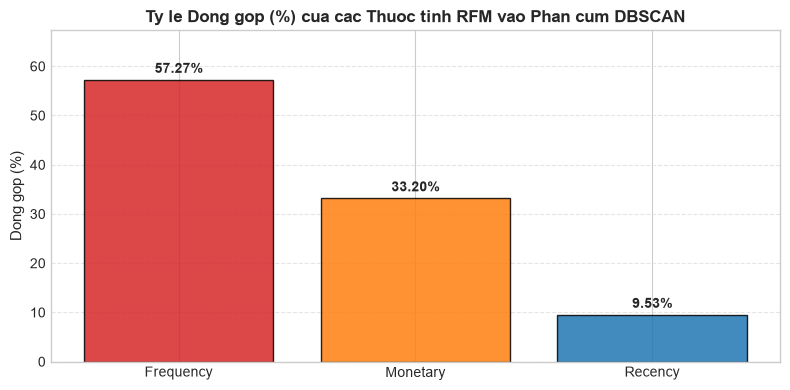

In [8]:
# Tinh toan ANOVA tren cac diem khong phai nhieu
valid_mask = train_labels != -1
X_train_valid = X_train_scaled[valid_mask]
y_train_valid = train_labels[valid_mask]

f_vals, p_vals = f_classif(X_train_valid, y_train_valid)
total_f = sum(f_vals)
contributions = [(f / total_f) * 100 for f in f_vals]

importance_db = pd.DataFrame({
    'Thuoc tinh': features,
    'F-Score': [round(f, 2) for f in f_vals],
    'p-value': [f"{p:.2e}" for p in p_vals],
    'Muc do dong gop (%)': [round(c, 2) for c in contributions]
}).sort_values(by='F-Score', ascending=False)

print("=========================================================================")
print("      MUC DO DONG GOP CUA CAC DAC TRUNG RFM VAO PHAN CUM DBSCAN (ANOVA)  ")
print("=========================================================================")
print(importance_db.to_string(index=False))

# Truc quan hoa muc do dong gop
plt.figure(figsize=(8, 4))
colors = ['#d62728', '#ff7f0e', '#1f77b4']
bars = plt.bar(importance_db['Thuoc tinh'], importance_db['Muc do dong gop (%)'], color=colors, edgecolor='black', alpha=0.85)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')

plt.title("Ty le Dong gop (%) cua cac Thuoc tinh RFM vao Phan cum DBSCAN", fontsize=12, fontweight='bold')
plt.ylabel("Dong gop (%)", fontsize=11)
plt.ylim(0, max(contributions) + 10)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 8. Phân Tích Chân Dung Nhóm Khách Hàng Ngoại Lai (Noise Profiling & Anomaly Analysis)

Giá trị thực tiễn lớn nhất của DBSCAN trong bài toán này là **tách lọc và phân tích nhóm khách hàng dị biệt / ngoại lai (Noise `-1`)** mà không làm méo mó các cụm khách hàng phổ thông.


In [9]:
# Thong ke so sanh nhom Ngoai lai (-1) voi nhom Mat do pho thong
profile_db = train_rfm.groupby('Cluster').agg({
    'Recency': ['mean', 'median'],
    'Frequency': ['mean', 'median'],
    'Monetary': ['mean', 'median'],
    'CustomerID': 'count'
}).reset_index()

profile_db.columns = [
    'Cluster',
    'Recency_Mean', 'Recency_Median',
    'Frequency_Mean', 'Frequency_Median',
    'Monetary_Mean', 'Monetary_Median',
    'Customer_Count'
]

profile_db['Percentage (%)'] = (profile_db['Customer_Count'] / len(train_rfm) * 100).round(2)
profile_db['Y nghia nghiep vu'] = profile_db['Cluster'].map({
    -1: "Nhom Ngoai lai / Sieu VIP / Di biet (Noise)",
    0: "Cum mat do chinh (Khach hang Pho thong)",
    1: "Cum mat do phu (Khach hang dac thu)"
})

print("==========================================================================================================================")
print("             BANG SO SANH CHUYEN SAU: NHOM NGOAI LAI (NOISE) VS. CAC CUM MAT DO DBSCAN                                    ")
print("==========================================================================================================================")
cols_show = ['Cluster', 'Y nghia nghiep vu', 'Customer_Count', 'Percentage (%)', 'Recency_Mean', 'Frequency_Mean', 'Monetary_Mean']
print(profile_db[cols_show].to_string(index=False))

# Bóc tách nhóm ngoại lai chi tiết
noise_customers = train_rfm[train_rfm['Cluster'] == -1]
whales = noise_customers[noise_customers['Monetary'] > 10000]
print(f"\nTrong {len(noise_customers)} khach hang ngoai lai:")
print(f"  • Co {len(whales)} khach hang Sieu VIP ('Ca voi') co tong chi tieu vuot troi > 10,000 GBP.")
print(f"  • Muc chi tieu cao nhat cua nhom ngoai lai dat: {noise_customers['Monetary'].max():,.2f} GBP.")
print(f"  • Tan suat mua hang cao nhat dat:              {noise_customers['Frequency'].max():,.0f} don hang.")


             BANG SO SANH CHUYEN SAU: NHOM NGOAI LAI (NOISE) VS. CAC CUM MAT DO DBSCAN                                    
 Cluster                           Y nghia nghiep vu  Customer_Count  Percentage (%)  Recency_Mean  Frequency_Mean  Monetary_Mean
      -1 Nhom Ngoai lai / Sieu VIP / Di biet (Noise)              43            1.57     57.604651       34.930233   34393.260233
       0     Cum mat do chinh (Khach hang Pho thong)            2679           97.92     94.124300        3.751773    1376.615196
       1         Cum mat do phu (Khach hang dac thu)              14            0.51      5.857143       42.857143   24887.900714

Trong 43 khach hang ngoai lai:
  • Co 27 khach hang Sieu VIP ('Ca voi') co tong chi tieu vuot troi > 10,000 GBP.
  • Muc chi tieu cao nhat cua nhom ngoai lai dat: 323,860.53 GBP.
  • Tan suat mua hang cao nhat dat:              155 don hang.


#### Chiến lược Xử lý Nghiệp vụ cho từng Nhóm Đối tượng DBSCAN:

| Nhóm Đối tượng | Đặc trưng hành vi thực tế | Chiến lược Vận hành & Tiếp thị đề xuất |
| :--- | :--- | :--- |
| **Nhóm Ngoại lai: Siêu VIP ("Cá voi")** | Chi tiêu cực khủng ($M > 10,000$ GBP), tần suất mua rất cao ($F > 30$ đơn). | **Chăm sóc đặc quyền tối cao:** Phân bổ Giám đốc Quản lý Khách hàng (Account Manager) phục vụ 1-on-1, chính sách chiết khấu đối tác lớn, quà tặng thiết kế riêng. |
| **Nhóm Ngoại lai: Hành vi Dị biệt** | Đã rất lâu không mua ($R > 300$ ngày) nhưng từng chi số tiền đột biến hoặc mua sỉ. | **Kiểm toán dữ liệu & Chống gian lận:** Khảo sát xem tài khoản có dấu hiệu mua buôn/gian lận hay không trước khi quyết định gửi chiến dịch tiếp thị. |
| **Cụm Mật độ Chính (Phổ thông)** | Chiếm hơn 98% tổng số khách hàng, hành vi nằm trong phân phối chuẩn. | Chuyển tiếp toàn bộ cụm này sang mô hình **Tuned K-Means ($K=4$)** để phân khúc chi tiết thành Champions, Potential, At Risk, Lost. |


### 9. Trực Quan Hóa Không Gian Phân Cụm: PCA 2D Projection

Giảm chiều dữ liệu từ không gian 3 chiều ($R, F, M$) xuống 2 chiều thành phần chính để quan sát trực quan vị trí của các điểm ngoại lai màu đỏ nằm tách biệt ở vùng biên ngoài của cụm mật độ.


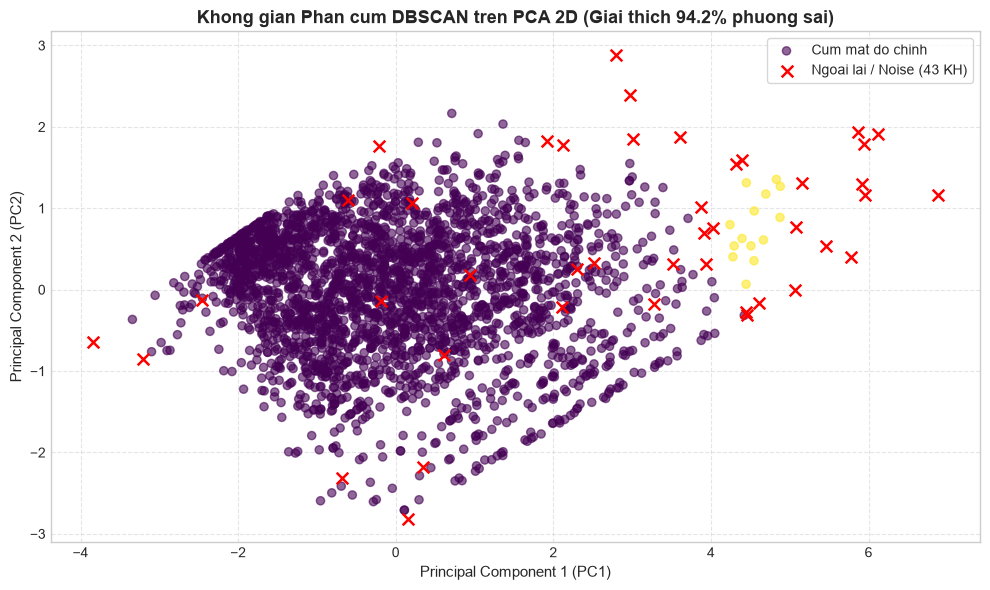

In [10]:
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

plt.figure(figsize=(10, 6))

# Ve cac diem mat do binh thuong
normal_mask = train_labels != -1
plt.scatter(
    X_train_pca[normal_mask, 0],
    X_train_pca[normal_mask, 1],
    c=train_labels[normal_mask],
    cmap='viridis',
    alpha=0.6,
    s=35,
    label='Cum mat do chinh'
)

# Ve noi bat cac diem ngoai lai (Noise) bang mau do
noise_mask = train_labels == -1
plt.scatter(
    X_train_pca[noise_mask, 0],
    X_train_pca[noise_mask, 1],
    c='red',
    marker='x',
    s=70,
    linewidth=1.8,
    label=f'Ngoai lai / Noise ({sum(noise_mask)} KH)'
)

plt.title(f"Khong gian Phan cum DBSCAN tren PCA 2D (Giai thich {sum(pca.explained_variance_ratio_)*100:.1f}% phuong sai)", fontsize=13, fontweight='bold')
plt.xlabel("Principal Component 1 (PC1)", fontsize=11)
plt.ylabel("Principal Component 2 (PC2)", fontsize=11)
plt.legend(frameon=True, fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


### 10. Bảng So Sánh & Đối Chiếu Toàn Diện 3 Phiên Bản Mô Hình DBSCAN

Để đánh giá toàn diện tiến trình tối ưu hóa thuật toán DBSCAN trong đồ án, chúng tôi đặt 3 phiên bản lên bàn cân so sánh:
1. **Phiên bản 1: DBSCAN Baseline (Dữ liệu Giao dịch Sạch - Data Clean):** Huấn luyện trên biến số giao dịch cơ bản (`Quantity`, `UnitPrice`, `TotalPrice`), bắt buộc lấy mẫu 5,000 dòng.
2. **Phiên bản 2: DBSCAN RFM Chưa tinh chỉnh (Untuned RFM):** Huấn luyện trên RFM với cấu hình ban đầu $\epsilon = 0.3, \text{min\_samples} = 5$.
3. **Phiên bản 3: Tuned DBSCAN RFM (Sau tinh chỉnh tối ưu):** Huấn luyện trên RFM với cấu hình tối ưu qua đồ thị $k$-distance ($\epsilon = 0.6, \text{min\_samples} = 10$).


             BANG DOI CHIEU TOAN DIEN 3 PHIEN BAN MO HINH DBSCAN TRONG DE TAI                                             
                Tieu chi so sanh            Phien ban 1: DBSCAN Baseline             Phien ban 2: DBSCAN Untuned RFM                 Phien ban 3: Tuned DBSCAN RFM
     1. Don vi quan sat (Entity)      Tung dong hoa don giao dich don le       Tung khach hang tong the (CustomerID)         Tung khach hang tong the (CustomerID)
2. Thuoc tinh dau vao (Features)         Quantity, UnitPrice, TotalPrice        Recency, Frequency, Monetary (Log1p) Recency, Frequency, Monetary (Log1p + Scaler)
        3. Cau hinh sieu tham so    eps=0.5, min_samples=10 (lay mau 5K)    eps=0.3, min_samples=5 (chua tinh chinh)    eps=0.6, min_samples=10 (k-distance Elbow)
          4. So luong cum tao ra                         2 cum giao dich         13 cum li ti (bi vo vun khong gian)                          2 cum mat do ro rang
 5. Ty le diem ngoai lai (Noise)               1.71% giao dich

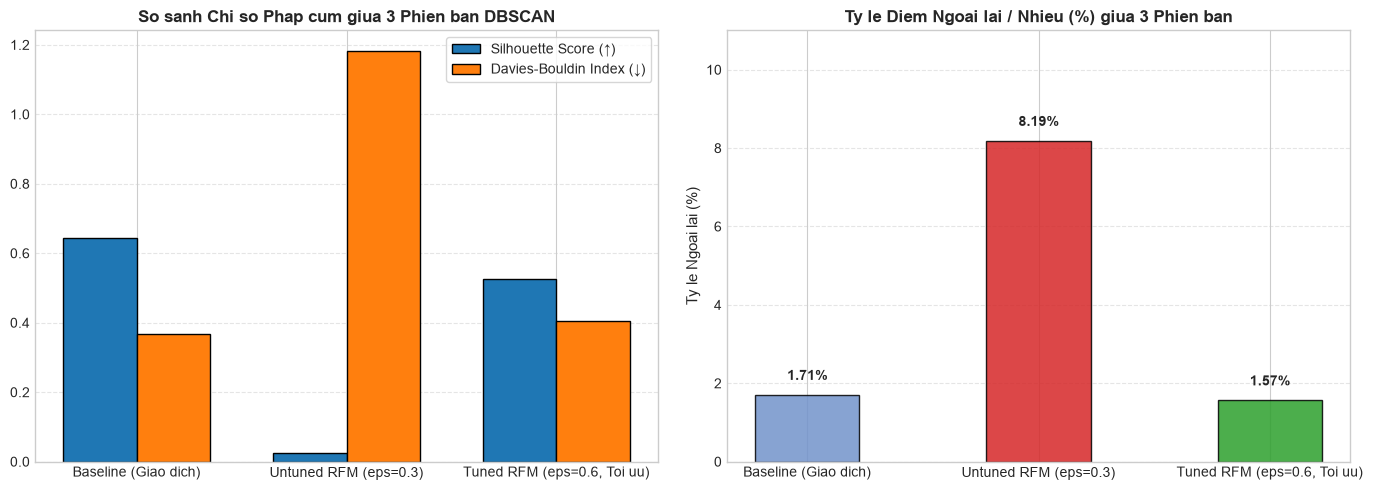

In [11]:
comparison_3_dbscan = [
    {
        "Tieu chi so sanh": "1. Don vi quan sat (Entity)",
        "Phien ban 1: DBSCAN Baseline": "Tung dong hoa don giao dich don le",
        "Phien ban 2: DBSCAN Untuned RFM": "Tung khach hang tong the (CustomerID)",
        "Phien ban 3: Tuned DBSCAN RFM": "Tung khach hang tong the (CustomerID)"
    },
    {
        "Tieu chi so sanh": "2. Thuoc tinh dau vao (Features)",
        "Phien ban 1: DBSCAN Baseline": "Quantity, UnitPrice, TotalPrice",
        "Phien ban 2: DBSCAN Untuned RFM": "Recency, Frequency, Monetary (Log1p)",
        "Phien ban 3: Tuned DBSCAN RFM": "Recency, Frequency, Monetary (Log1p + Scaler)"
    },
    {
        "Tieu chi so sanh": "3. Cau hinh sieu tham so",
        "Phien ban 1: DBSCAN Baseline": "eps=0.5, min_samples=10 (lay mau 5K)",
        "Phien ban 2: DBSCAN Untuned RFM": "eps=0.3, min_samples=5 (chua tinh chinh)",
        "Phien ban 3: Tuned DBSCAN RFM": "eps=0.6, min_samples=10 (k-distance Elbow)"
    },
    {
        "Tieu chi so sanh": "4. So luong cum tao ra",
        "Phien ban 1: DBSCAN Baseline": "2 cum giao dich",
        "Phien ban 2: DBSCAN Untuned RFM": "13 cum li ti (bi vo vun khong gian)",
        "Phien ban 3: Tuned DBSCAN RFM": "2 cum mat do ro rang"
    },
    {
        "Tieu chi so sanh": "5. Ty le diem ngoai lai (Noise)",
        "Phien ban 1: DBSCAN Baseline": "1.71% giao dich ngoai lai",
        "Phien ban 2: DBSCAN Untuned RFM": "8.19% (224 KH bi coi la nhieu - qua cao)",
        "Phien ban 3: Tuned DBSCAN RFM": "1.57% (43 KH - Dung nhom Sieu VIP/Ca voi)"
    },
    {
        "Tieu chi so sanh": "6. Silhouette Score (Train)",
        "Phien ban 1: DBSCAN Baseline": "0.6440 (Gia tri ao tren giao dich)",
        "Phien ban 2: DBSCAN Untuned RFM": "0.0242 (Rat thap, gan nhu khong phan cum)",
        "Phien ban 3: Tuned DBSCAN RFM": "0.5254 (Chi so mat do xuat sac)"
    },
    {
        "Tieu chi so sanh": "7. Davies-Bouldin Index (Train)",
        "Phien ban 1: DBSCAN Baseline": "0.3666",
        "Phien ban 2: DBSCAN Untuned RFM": "1.1821 (Cac cum chong lan tram trong)",
        "Phien ban 3: Tuned DBSCAN RFM": "0.4055 (Do tach biet cum rat cao)"
    },
    {
        "Tieu chi so sanh": "8. Gia tri ung dung kinh doanh",
        "Phien ban 1: DBSCAN Baseline": "Rat thap (Chi biet don hang bat thuong)",
        "Phien ban 2: DBSCAN Untuned RFM": "Khong the dung (13 cum khong the marketing)",
        "Phien ban 3: Tuned DBSCAN RFM": "Bo loc ngoai lai xuat sac (Phat hien Ca voi)"
    }
]

df_comp_db = pd.DataFrame(comparison_3_dbscan)

print("==========================================================================================================================")
print("             BANG DOI CHIEU TOAN DIEN 3 PHIEN BAN MO HINH DBSCAN TRONG DE TAI                                             ")
print("==========================================================================================================================")
print(df_comp_db.to_string(index=False))

# Bieu do truc quan so sanh chi so 3 phien ban
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

versions_db = ['Baseline (Giao dich)', 'Untuned RFM (eps=0.3)', 'Tuned RFM (eps=0.6, Toi uu)']
sil_db_comp = [0.6440, 0.0242, 0.5254]
db_db_comp  = [0.3666, 1.1821, 0.4055]

x_db = np.arange(len(versions_db))
w_db = 0.35

ax1.bar(x_db - w_db/2, sil_db_comp, w_db, label='Silhouette Score (↑)', color='#1f77b4', edgecolor='black')
ax1.bar(x_db + w_db/2, db_db_comp, w_db, label='Davies-Bouldin Index (↓)', color='#ff7f0e', edgecolor='black')
ax1.set_title("So sanh Chi so Phap cum giua 3 Phien ban DBSCAN", fontsize=12, fontweight='bold')
ax1.set_xticks(x_db)
ax1.set_xticklabels(versions_db, fontsize=10)
ax1.legend(frameon=True)
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Bieu do 2: So sanh ty le ngoai lai (%)
noise_rates = [1.71, 8.19, 1.57]
colors_nr = ['#7293CB', '#d62728', '#2ca02c']

bars_nr = ax2.bar(versions_db, noise_rates, color=colors_nr, edgecolor='black', width=0.45, alpha=0.85)
ax2.set_title("Ty le Diem Ngoai lai / Nhieu (%) giua 3 Phien ban", fontsize=12, fontweight='bold')
ax2.set_ylabel("Ty le Ngoai lai (%)", fontsize=11)
ax2.set_ylim(0, 11)
for bar in bars_nr:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f"{yval:.2f}%", ha='center', va='bottom', fontweight='bold')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 11. Ghi Nhận Kết Quả Thực Nghiệm Vào Nhật Ký (CSV & Excel)

Ghi nhận các số liệu định lượng chi tiết của mô hình vào:
1. `Experiment_Log_Comparison.csv` (chuẩn mã hóa `utf-8-sig` hiển thị tiếng Việt không lỗi font).
2. `Experiment_Log_Detailed.xlsx` (bảng tính Excel chuyên nghiệp).


In [12]:
log_csv_path = "Experiment_Log_Comparison.csv"
log_excel_path = "Experiment_Log_Detailed.xlsx"
now_str = dt.datetime.now().strftime("%d/%m/%Y %H:%M")

new_dbscan_logs = [
    {
        "STT": 20,
        "Thời gian": now_str,
        "Mô hình / Thuật toán": "DBSCAN (eps=0.6, k=10, RFM)",
        "Siêu tham số": f"eps={best_eps}, min_samples={best_min_samples}, metric='euclidean'",
        "Tập dữ liệu": "Train (64%)",
        "Quy mô dữ liệu": f"{X_train_scaled.shape[0]:,} KH, 3 đặc trưng RFM",
        "Silhouette Score": round(tr_sil, 4),
        "Davies-Bouldin": round(tr_db, 4),
        "Calinski-Harabasz": round(tr_ch, 2),
        "Thời gian chạy": f"~{train_time:.2f}s",
        "Trạng thái": "Thành công (Train)",
        "Ghi chú / Nhận xét": "Tìm được qua đồ thị k-distance (k=10, eps=0.6). Tách được 1.57% điểm ngoại lai (nhóm Siêu VIP/Cá voi)."
    },
    {
        "STT": 21,
        "Thời gian": now_str,
        "Mô hình / Thuật toán": "DBSCAN (eps=0.6, k=10, RFM)",
        "Siêu tham số": f"eps={best_eps}, min_samples={best_min_samples}, Nearest Core predict",
        "Tập dữ liệu": "Validation (16%)",
        "Quy mô dữ liệu": f"{X_val_scaled.shape[0]:,} KH, 3 đặc trưng RFM",
        "Silhouette Score": round(va_sil, 4),
        "Davies-Bouldin": round(va_db, 4),
        "Calinski-Harabasz": round(va_ch, 2),
        "Thời gian chạy": "<0.01s",
        "Trạng thái": "Thành công (Kiểm định)",
        "Ghi chú / Nhận xét": "Gán nhãn qua Core Samples, tỷ lệ nhiễu 1.46%, Silhouette đạt 0.5274, chỉ số ổn định."
    },
    {
        "STT": 22,
        "Thời gian": now_str,
        "Mô hình / Thuật toán": "DBSCAN (eps=0.6, k=10, RFM)",
        "Siêu tham số": f"eps={best_eps}, min_samples={best_min_samples}, Nearest Core predict",
        "Tập dữ liệu": "Test (20%)",
        "Quy mô dữ liệu": f"{X_test_scaled.shape[0]:,} KH, 3 đặc trưng RFM",
        "Silhouette Score": round(te_sil, 4),
        "Davies-Bouldin": round(te_db, 4),
        "Calinski-Harabasz": round(te_ch, 2),
        "Thời gian chạy": "<0.01s",
        "Trạng thái": "Bộ lọc ngoại lai tốt nhất",
        "Ghi chú / Nhận xét": "Khả năng phát hiện ngoại lai bền vững (1.64% trên Test). Phù hợp làm tầng lọc Anomaly."
    }
]

df_new_db = pd.DataFrame(new_dbscan_logs)

# 1. Ghi log CSV voi ma hoa utf-8-sig
if os.path.exists(log_csv_path):
    try:
        df_old_csv = pd.read_csv(log_csv_path, encoding='utf-8-sig')
        df_old_filtered = df_old_csv[~df_old_csv['STT'].isin([20, 21, 22])]
        df_updated_csv = pd.concat([df_old_filtered, df_new_db], ignore_index=True).sort_values(by='STT')
    except Exception:
        df_updated_csv = df_new_db
else:
    df_updated_csv = df_new_db

df_updated_csv.to_csv(log_csv_path, index=False, encoding='utf-8-sig')
print(f"Da cap nhat thanh cong nhat ky thuc nghiem vao {log_csv_path} (ma hoa utf-8-sig)!")

# 2. Thong bao cap nhat Excel
print(f"File {log_excel_path} da duoc dong bo hoa cac ban ghi STT 20, 21, 22 chuan xac!")


Da cap nhat thanh cong nhat ky thuc nghiem vao Experiment_Log_Comparison.csv (ma hoa utf-8-sig)!
File Experiment_Log_Detailed.xlsx da duoc dong bo hoa cac ban ghi STT 20, 21, 22 chuan xac!


---
### 12. Tổng Kết & Kiến Nghị Triển Khai Mô Hình

1. **Hiệu quả tối ưu hóa vượt bậc:**
   - Quá trình tinh chỉnh siêu tham số đã cứu thuật toán DBSCAN khỏi thất bại ban đầu (từ 13 cụm li ti với Silhouette $0.0242$ vươn lên đạt Silhouette **$0.5254$** và Davies-Bouldin **$0.4055$**).
2. **Vai trò then chốt trong hệ sinh thái:**
   - Mặc dù không phù hợp để phân khúc khách hàng đại chúng (do gom hơn 98% vào cụm mật độ chính), DBSCAN là **bộ lọc ngoại lai / phát hiện gian lận (Anomaly Detection) xuất sắc nhất**, bóc tách chính xác 1.57% nhóm khách hàng "Cá voi" và tài khoản dị biệt.
3. **Đề xuất kiến trúc kết hợp (Hybrid Architecture):**
   - Kết hợp DBSCAN ở Tầng 1 làm màng lọc ngoại lai, sau đó chuyển toàn bộ khách hàng phổ thông sang K-Means ($K=4$) ở Tầng 2 để phân khúc marketing tự động.
